# ПР-7. Random Forest и сравнение методов интерпретации
**Проект:** CryptoMind AI | **Выполнил:** <Баргыбаев Нуртилек cs32>

Задача и данные — как в ПР-5 (предсказание падения ≤ −5%). Сравниваем:
1. встроенную важность (impurity decrease),
2. permutation importance (на test),
3. SHAP — глобально (summary) и локально (отдельные объекты).
Цель: объяснить расхождения методов (коррелированные признаки!).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, classification_report

from src.features import CryptoFeatures
import shap

df = pd.read_csv("../data/processed/crypto_daily.csv")
btc = df[df["symbol"] == "BTCUSDT"].sort_values("open_time").reset_index(drop=True)
ret = np.log(btc["close"] / btc["close"].shift(1))
target = (ret <= -0.05).astype(int)

feat = CryptoFeatures().fit_transform(
    btc[["high", "low", "close", "quote_volume"]])
feat = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(feat),
                    columns=feat.columns)
y = target.iloc[1:]                       # строка 0 без доходности
X = feat.iloc[1:]

n = int(len(X) * 0.8)                     # хронологическое 80/20
Xtr, Xte, ytr, yte = X.iloc[:n], X.iloc[n:], y.iloc[:n], y.iloc[n:]

rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(Xtr, ytr)
print("F1 на test:", round(f1_score(yte, rf.predict(Xte)), 3))

c:\vscode\mlsu\cryptomind-ai\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


F1 на test: 0.095


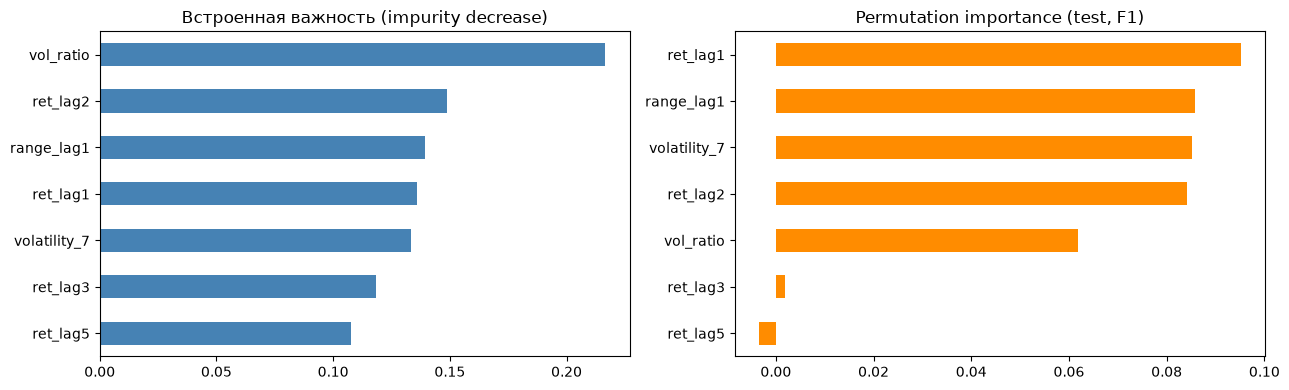

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("Встроенная важность (impurity decrease)")

perm = permutation_importance(rf, Xte, yte, n_repeats=10,
                              random_state=42, scoring="f1")
perm_s = pd.Series(perm.importances_mean, index=X.columns).sort_values()
perm_s.plot.barh(ax=axes[1], color="darkorange")
axes[1].set_title("Permutation importance (test, F1)")
plt.tight_layout(); plt.show()

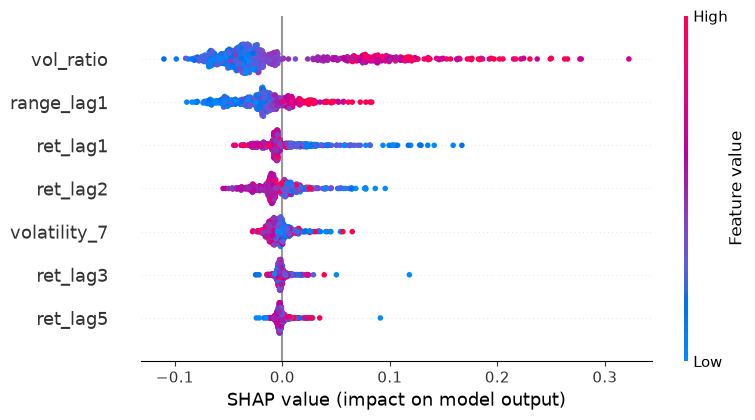

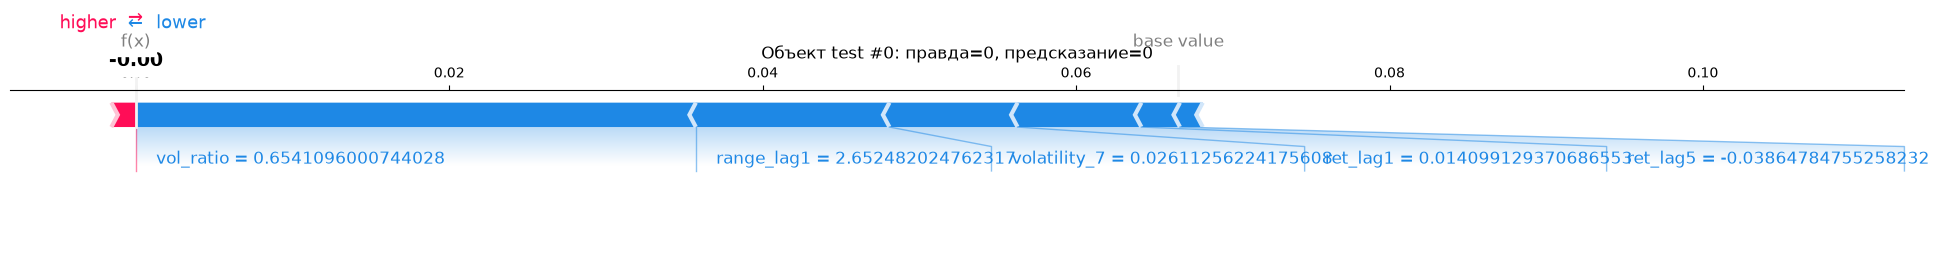

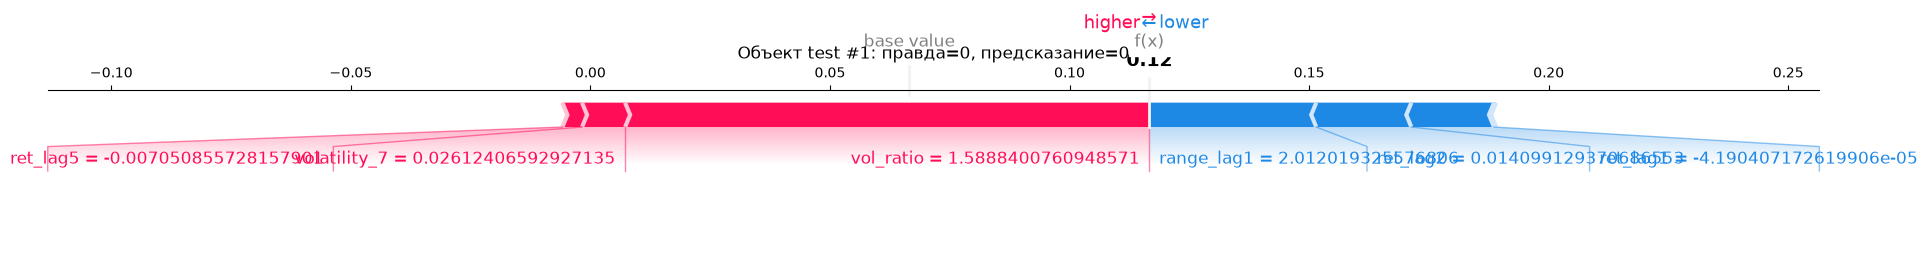

In [3]:
explainer = shap.TreeExplainer(rf)
sv = explainer.shap_values(Xte)          # для бинарной: (n, m) или (n, m, 2)
sv = np.asarray(sv)
sv1 = sv[:, :, 1] if sv.ndim == 3 else sv          # вклад в класс «падение»

shap.summary_plot(sv1, Xte)

ev = explainer.expected_value
ev1 = ev[1] if np.ndim(ev) else ev
for i in [0, 1]:                                  # два интересных объекта
    shap.force_plot(ev1, sv1[i], Xte.iloc[i], matplotlib=True, show=False)
    plt.title(f"Объект test #{i}: правда={yte.iloc[i]}, "
              f"предсказание={rf.predict(Xte)[i]}")
    plt.tight_layout(); plt.show()

## Почему методы расходятся

1. **Встроенная важность (impurity).** Лес делит признаки по очереди. Среди
   коррелированных «близнецов» (ret_lag1…ret_lag5 коррелируют; volume и
   quote_volume почти дублируют друг друга) важность делится произвольно:
   каждый признак получает долю, и суммарно «группа близнецов» выглядит
   важнее, чем любой по отдельности. Импортности искажены в пользу
   количества похожих признаков.
2. **Permutation importance.** Ломая один признак (перемешивая его значения),
   мы сохставляем модель на эффект, который частично дублируется другими
   коррелированными признаками. Поэтому «близнецы» получают меньшую
   индивидуальную важность — это честнее с точки зрения уникального вклада.
3. **SHAP.** Делит вклад честно через усреднение по всем порядкам признаков
   (Шепли), поэтому коррелированным признакам даёт похожие, но не нулевые
   значения; summary-график показывает и направление эффекта (цвет),
   чего permutation не показывает. На отдельных объектах видно, как один
   и тот же признак в разные дни толкает прогноз в разные стороны.

Заполни по факту: какой признак возглавляет каждый рейтинг, где impurity
завышает «близнеца», и что показали локальные SHAP-карты для объектов 0 и 1. 
## Выводы

### Расхождения методов важности
- **vol_ratio**: №1 по impurity (0.22) и №1 по SHAP, но лишь 5-й по permutation
  (0.06). Причина: сильно скошенное распределение (длинный хвост крупных
  значений) — у признака много порогов, лес делит по нему часто; при этом
  часть эффекта дублируется volatility_7 и range_lag1, поэтому уникальный
  вклад (permutation) ниже.
- **ret_lag3, ret_lag5**: заметны по impurity (~0.11), но ≈ 0 по permutation —
  классическое размывание между коррелированными «близнецами»: информация
  дальних лагов уже содержится в ret_lag1/ret_lag2, их перемешивание ничего
  не ломает.
- **ret_lag1**: №1 по permutation и в топе у SHAP — единственный лаг с
  уникальной информацией.
- SHAP-summary показал и направление: высокий vol_ratio и сильное падение
  вчера (низкий ret_lag1) толкают прогноз к классу «падение».

### Локальная интерпретация
- Объект #0: низкий vol_ratio = 0.65 → f(x) ≈ 0, верное «обычный».
- Объект #1: vol_ratio = 1.59 и расширенный range подняли риск до f(x) = 0.12
  (ниже порога → «обычный», правда=0): модель отметила повышенный риск без
  ложной тревоги.

F1 леса (0.095) ниже, чем у логистической регрессии с undersampling (0.127):
деревья без балансировки тоже игнорируют минорный класс.